# Test: ответы, вероятности и расхождения моделей

Анализ использует сохранённые вероятности. Обучение и повторный inference не нужны. Истинных тестовых меток у нас нет, поэтому галереи показывают не доказанные ошибки, а расхождения и неуверенность.

**Легенда:** 101 T — ResNet101 на train; 101 TV — ResNet101 на train+val; Ens T и Ens TV — соответствующие ансамбли 101 без TTA + 50 с D4. Четыре варианта зависимы: ResNet101 входит в ансамбль. Совпадение четырёх ответов не равно четырём независимым подтверждениям.

Public scores со скриншота: 94.457%, 94.767%, 95.111%, 95.370%. Refit улучшил single на 0.310 п.п., ансамбль на 0.259 п.п. Разрыв с прежней val сам по себе не доказывает причину ухудшения: это другая выборка, а val многократно использовалась для выбора рецепта. Public score не сообщает ошибки отдельных ID и не обязательно относится ко всему test.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks': PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0,str(PROJECT_ROOT))
from src.test_analysis import (RECIPES, SHORT, load_test_analysis, test_case_table,
    analysis_tables, select_cases, compact_gallery, probability_detail)

SUITE = 'submissions_001'
RAW_DIR = PROJECT_ROOT/'data/raw'
PRIMARY = 'ensemble_train_val'  # для uncertainty/top2 pair
N_IMAGES = 40                  # можно30/50
SEED = 42
COLUMNS = 5
PAGE_SIZE = 20
THUMBNAIL = 144                # только экранное уменьшение, raw не меняется
CONFIDENCE = .95
REPORT_DIR = PROJECT_ROOT/'artifacts/logs/test_analysis_001'
REPORT_DIR.mkdir(parents=True,exist_ok=True)


## 1. Загрузка и проверки IDs/classes/probabilities

In [2]:
members, classes, source_members = load_test_analysis(PROJECT_ROOT, SUITE, RAW_DIR, include_sources=True)
cases = test_case_table(members, classes)
tables = analysis_tables(cases, classes)
cases.to_csv(REPORT_DIR/'test_cases.csv', index=False)
for name, table in tables.items(): table.to_csv(REPORT_DIR/f'{name}.csv', index=False)
public_scores = {'resnet101_train':.94457, 'resnet101_train_val':.94767,
                 'ensemble_train':.95111, 'ensemble_train_val':.95370}
overview = tables['confidence'].copy()
overview['public_score'] = overview.recipe.map(public_scores)
display(overview)
display(tables['pairwise'])
print('Any disagreement:', int(cases.disagree.sum()), '/', len(cases))
print('All agree:', int((~cases.disagree).sum()))
print('All four confident and disagree:', int((cases.disagree & cases.min_confidence.ge(CONFIDENCE)).sum()))


Any disagreement: 384 / 8299
All agree: 7915
All four confident and disagree: 0


,recipe,images,mean_confidence,median_margin,margin_below_0.1,confidence_below_0.8,mean_entropy,public_score
0,resnet101_train,8299,0.981157,0.999997,38,290,0.050320,0.94457
1,resnet101_train_val,8299,0.981594,0.999999,38,309,0.047898,0.94767
2,ensemble_train,8299,0.964678,0.999971,102,599,0.089441,0.95111
3,ensemble_train_val,8299,0.966388,0.999981,93,570,0.083041,0.95370


,left,right,different_answers,percent
0,resnet101_train,resnet101_train_val,313,3.771539
1,resnet101_train,ensemble_train,134,1.614652
2,resnet101_train,ensemble_train_val,271,3.265454
3,resnet101_train_val,ensemble_train,269,3.241354
4,resnet101_train_val,ensemble_train_val,142,1.711050
5,ensemble_train,ensemble_train_val,197,2.373780


## 2. Общая картина

Гистограммы confidence и разности top1−top2, распределение предсказанных классов и число расхождений. Сдвиг количества предсказаний не показывает качество отдельного класса. Эти таблицы не являются confusion matrix или оценкой калибровки — для них нужны истинные метки.


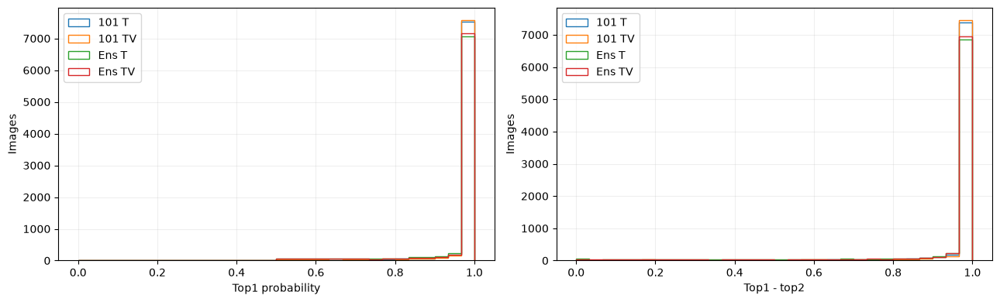

recipe,ensemble_train,ensemble_train_val,resnet101_train,resnet101_train_val
predicted_class,,,,
baseball_diamond,414,421,417,420
basketball_court,412,412,420,406
bridge,409,409,407,411
church,398,419,407,422
cloud,415,414,415,413
commercial_area,438,438,447,425
lake,422,424,424,414
medium_residential,424,412,418,415
overpass,416,424,418,427


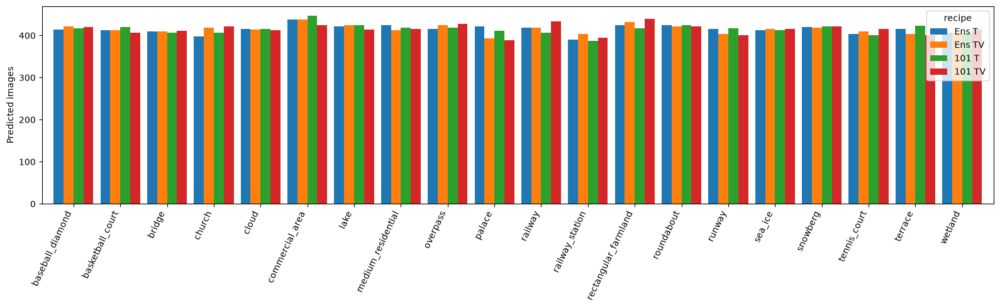

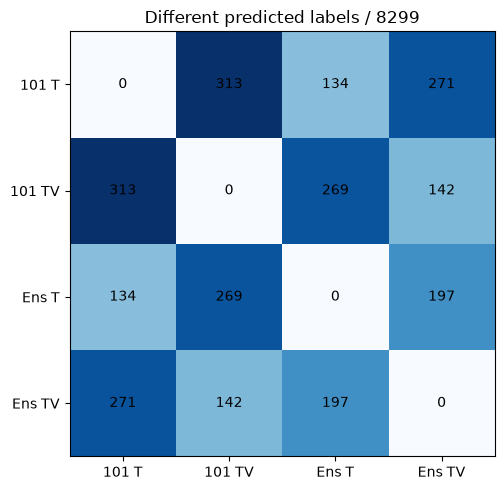

In [3]:
fig,axes = plt.subplots(1,2,figsize=(13,4))
for recipe in RECIPES:
    axes[0].hist(cases[f'{recipe}_p1'],bins=np.linspace(0,1,31),histtype='step',label=SHORT[recipe])
    axes[1].hist(cases[f'{recipe}_margin'],bins=np.linspace(0,1,31),histtype='step',label=SHORT[recipe])
axes[0].set(xlabel='Top1 probability',ylabel='Images'); axes[1].set(xlabel='Top1 - top2',ylabel='Images')
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); plt.show()
counts = tables['class_counts'].pivot(index='predicted_class',columns='recipe',values='count')
display(counts)
ax = counts.rename(columns=SHORT).plot.bar(figsize=(16,5),width=.85)
ax.set(ylabel='Predicted images',xlabel=''); plt.xticks(rotation=65,ha='right'); plt.tight_layout(); plt.show()
matrix = pd.DataFrame(0,index=RECIPES,columns=RECIPES)
for row in tables['pairwise'].itertuples(): matrix.loc[row.left,row.right]=matrix.loc[row.right,row.left]=row.different_answers
fig,ax=plt.subplots(figsize=(6,5)); ax.imshow(matrix,cmap='Blues')
ax.set_xticks(range(4),[SHORT[r] for r in RECIPES]); ax.set_yticks(range(4),[SHORT[r] for r in RECIPES])
for i in range(4):
    for j in range(4): ax.text(j,i,str(matrix.iloc[i,j]),ha='center',va='center')
ax.set_title('Different predicted labels / 8299'); fig.tight_layout(); plt.show()


## 3. Случайные 40 снимков: все четыре ответа

Фиксированная случайная выборка из всего test, независимо от классов и уверенности. Она помогает избежать просмотра только редких сложных объектов. Картинки компактные; любой ID можно затем открыть с top5 в последней секции.


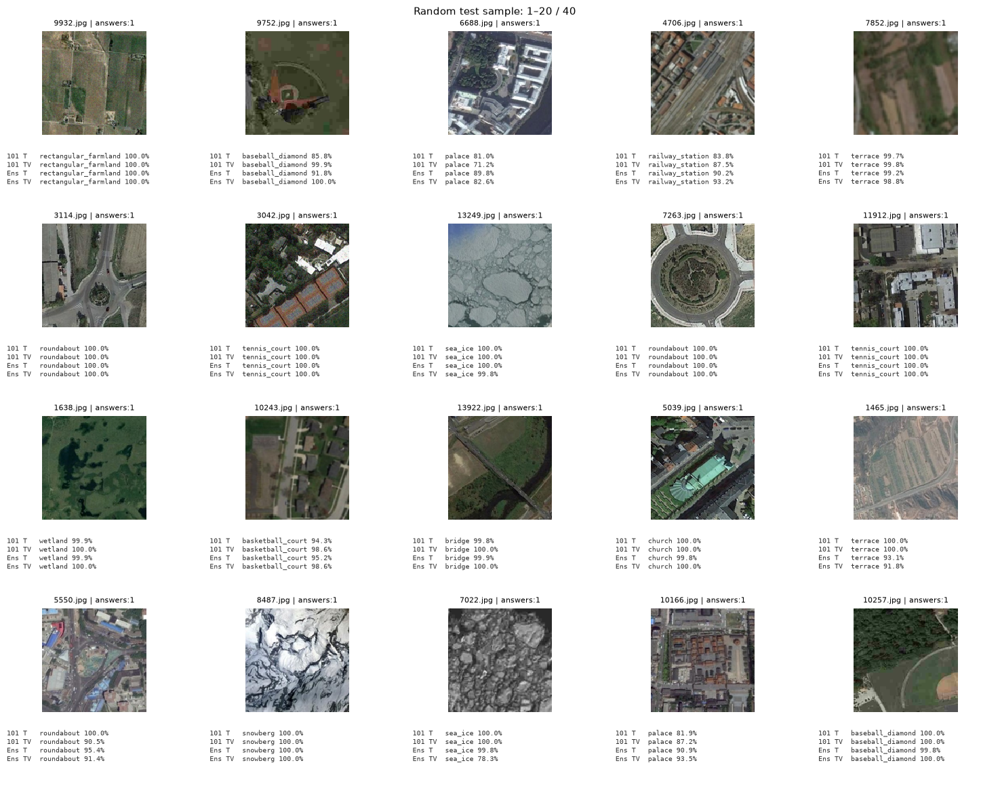

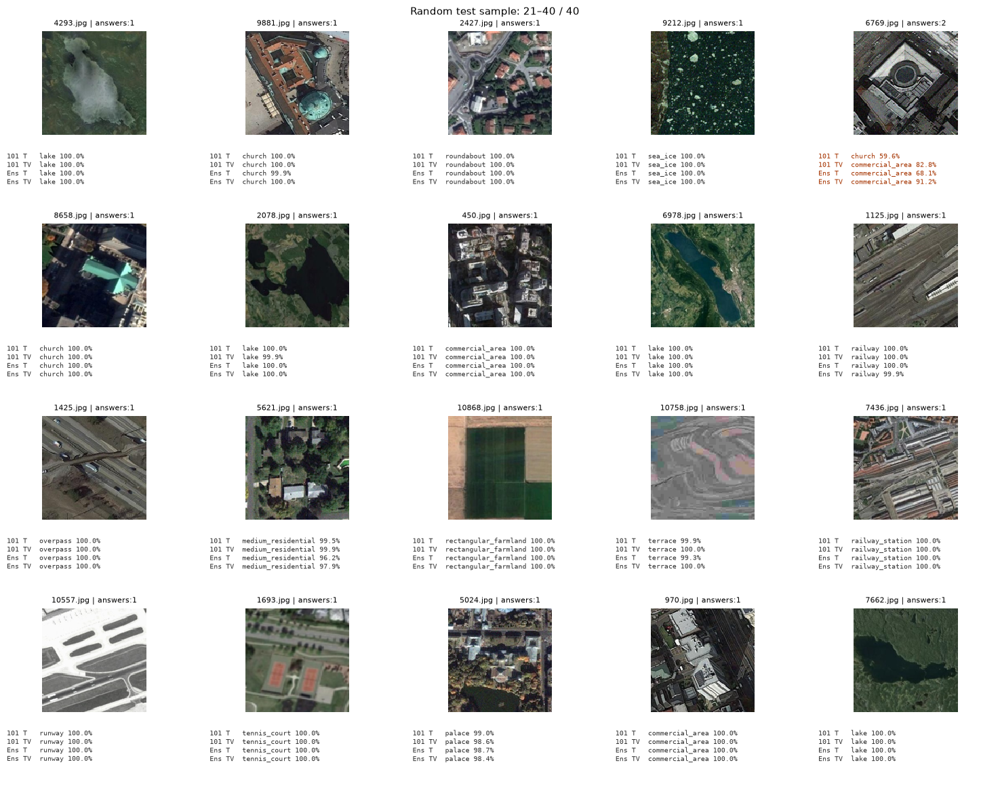

In [4]:
random_cases = select_cases(cases,'random',limit=N_IMAGES,seed=SEED)
random_cases[['id']].to_csv(REPORT_DIR/'random_ids.csv',index=False)
_ = compact_gallery(random_cases,RAW_DIR/'test',title='Random test sample',columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)


## 4. Самые неуверенные по PRIMARY

Сортируем по минимальной разности top1−top2: два ведущих класса почти равновероятны. Изменение PRIMARY позволяет посмотреть неуверенность другой модели. Альтернативная сортировка по энтропии: `selection='entropy'`.


,id,ensemble_train_val_class1,ensemble_train_val_p1,ensemble_train_val_class2,ensemble_train_val_p2,ensemble_train_val_margin,disagree
0,9717.jpg,terrace,0.499621,commercial_area,0.499617,0.000003,True
1,7792.jpg,palace,0.501397,church,0.498443,0.002954,True
2,9090.jpg,lake,0.501350,bridge,0.498244,0.003106,True
3,6872.jpg,railway,0.501414,overpass,0.497488,0.003927,False
4,35.jpg,rectangular_farmland,0.240287,baseball_diamond,0.235913,0.004374,True
5,12711.jpg,church,0.501880,medium_residential,0.497218,0.004663,True
6,879.jpg,palace,0.368012,commercial_area,0.362585,0.005427,True
7,7264.jpg,roundabout,0.503046,medium_residential,0.496900,0.006146,True
8,3426.jpg,commercial_area,0.460326,palace,0.454153,0.006174,True
9,12509.jpg,roundabout,0.487957,commercial_area,0.480830,0.007126,True


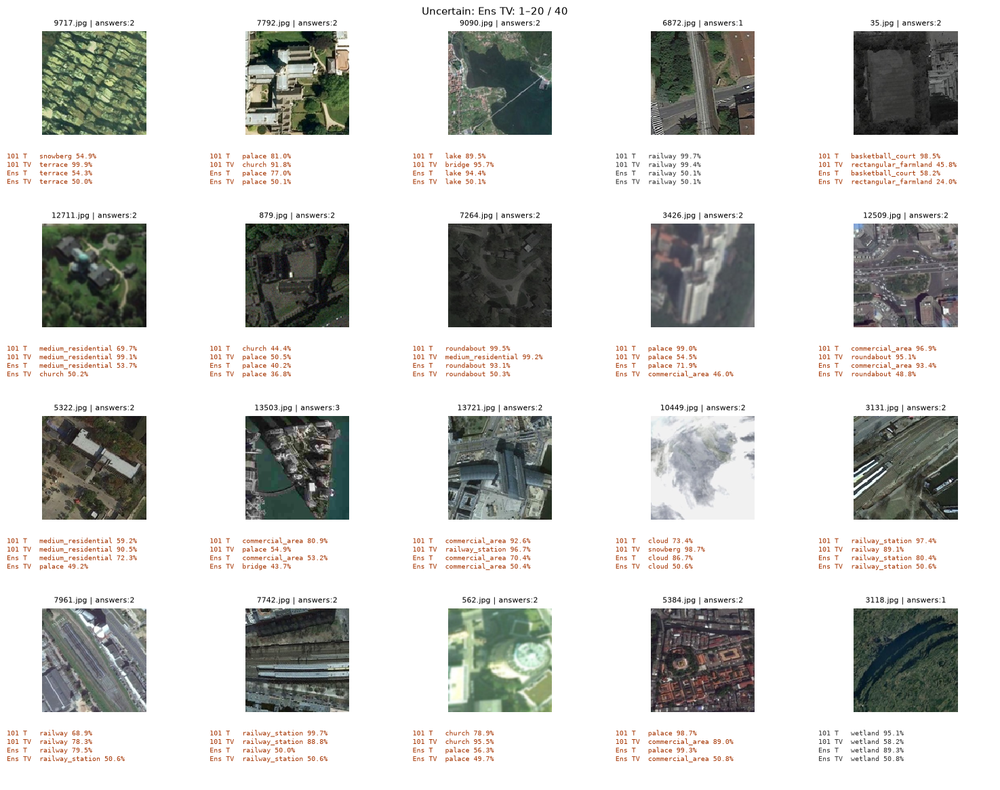

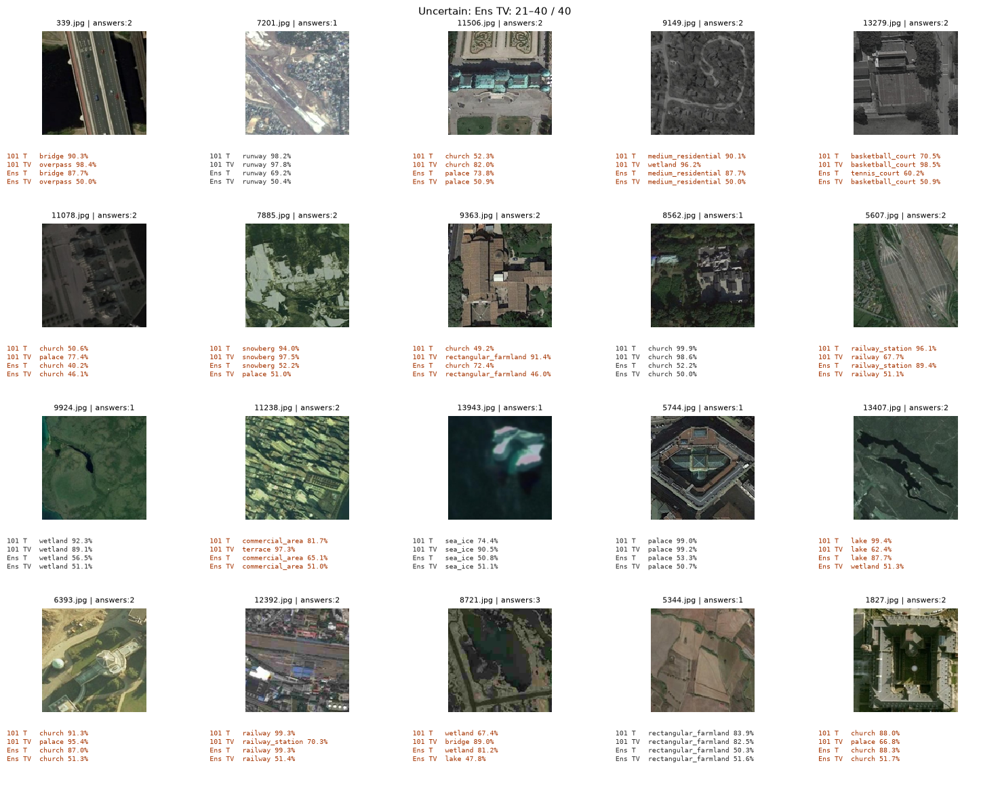

In [5]:
uncertain_cases = select_cases(cases,'uncertain',model=PRIMARY,limit=N_IMAGES)
display(uncertain_cases[['id',f'{PRIMARY}_class1',f'{PRIMARY}_p1',f'{PRIMARY}_class2',f'{PRIMARY}_p2',f'{PRIMARY}_margin','disagree']].head(15))
uncertain_cases[['id']].to_csv(REPORT_DIR/'uncertain_ids.csv',index=False)
_ = compact_gallery(uncertain_cases,RAW_DIR/'test',title=f'Uncertain: {SHORT[PRIMARY]}',columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)


## 5. Где различаются ответы

Выбираем разные top1, затем сортируем по Jensen–Shannon divergence — различию распределений вероятностей. Фильтры refit101/refit_ensemble показывают изменения после объединения train+val. JS используется только для диагностики; новая модель не обучается.


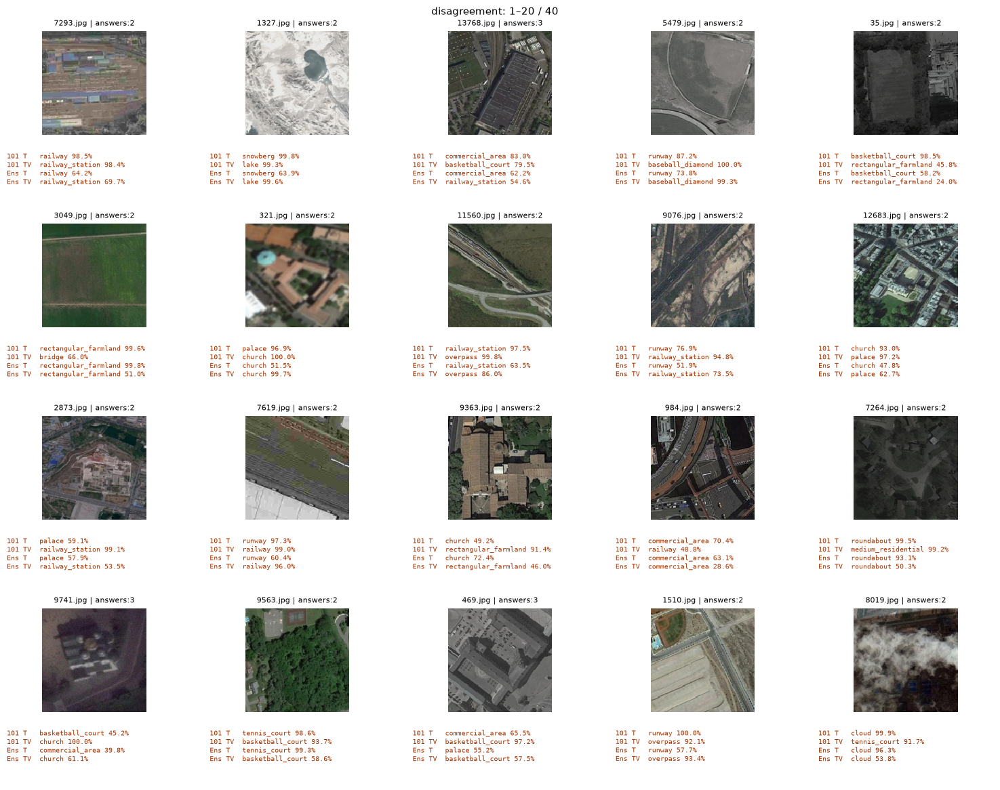

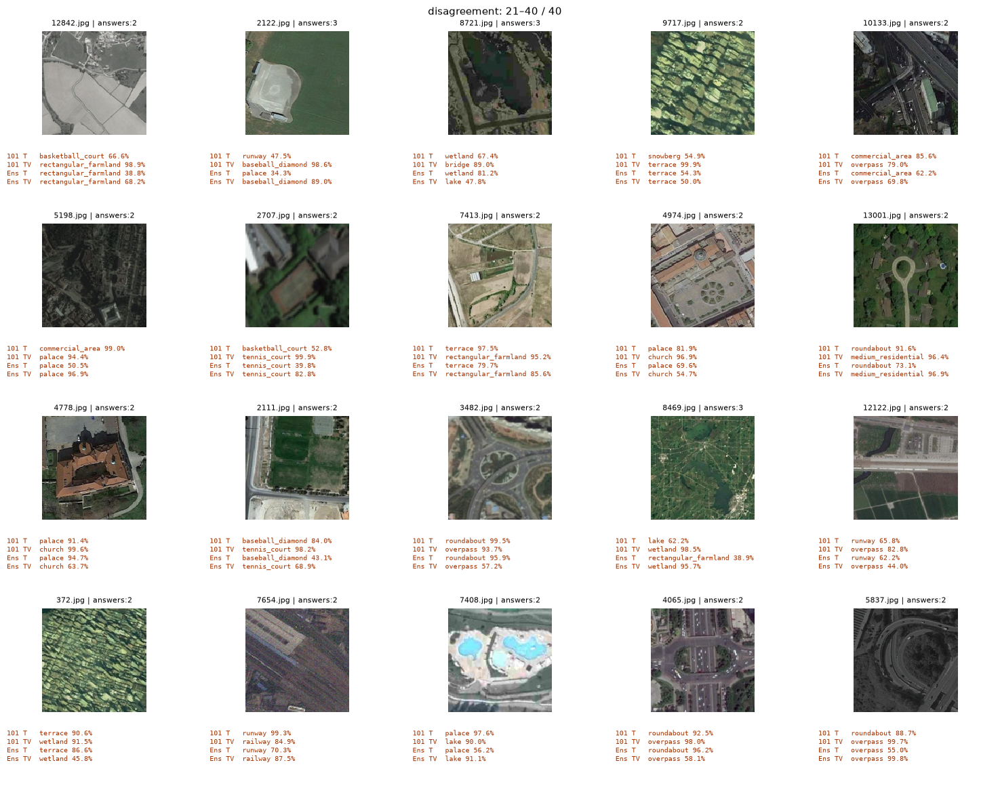

In [6]:
DISAGREEMENT_MODE = 'disagreement'  # либо refit101 / refit_ensemble
disagreement_cases = select_cases(cases,DISAGREEMENT_MODE,limit=N_IMAGES)
disagreement_cases[['id']].to_csv(REPORT_DIR/'disagreement_ids.csv',index=False)
_ = compact_gallery(disagreement_cases,RAW_DIR/'test',title=DISAGREEMENT_MODE,columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)


## 6. Уверенные противоречия и контроль уверенного согласия

В первой галерее две ResNet101 (train и train+val) выбирают разные классы, хотя обе дают своему ответу минимум 95%. Для другой пары измените compare в вызове select_cases. Требование одновременно высокой уверенности всех четырёх вариантов слишком строго: ансамбль часто снижает уверенность при споре участников. Во второй галерее — случайная выборка уверенных согласованных ответов. Согласие не доказывает правильность.


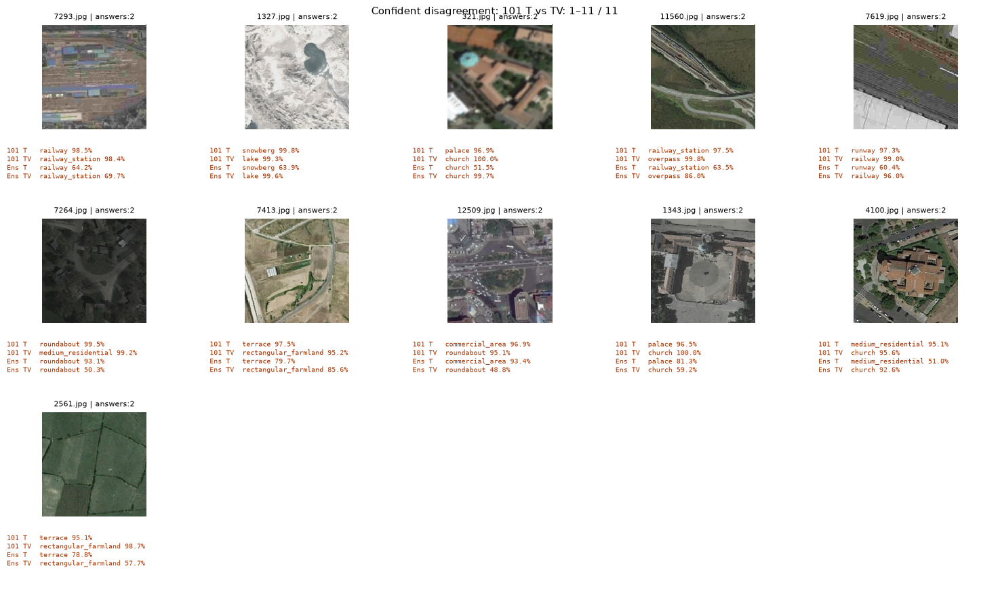

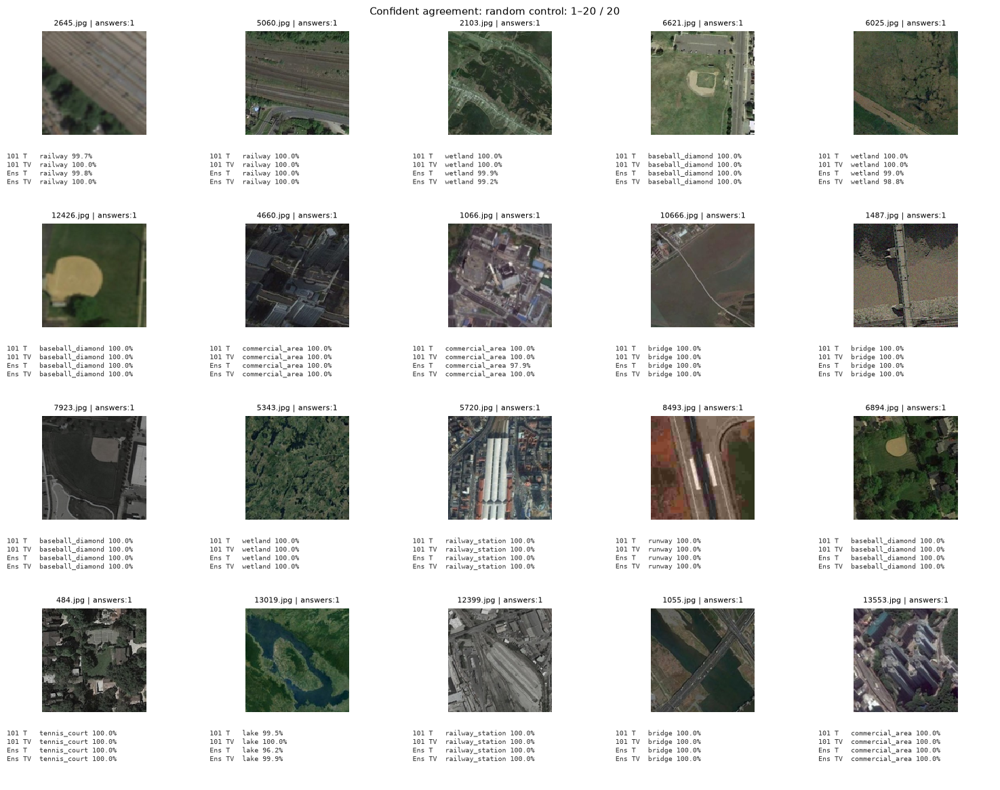

In [7]:
confident_cases = select_cases(cases,'confident_disagreement',limit=30,confidence=CONFIDENCE,compare=('resnet101_train','resnet101_train_val'))
confident_cases[['id']].to_csv(REPORT_DIR/'confident_disagreement_ids.csv',index=False)
_ = compact_gallery(confident_cases,RAW_DIR/'test',title='Confident disagreement: 101 T vs TV',columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)
agreement_cases = select_cases(cases,'confident_agreement',limit=20,confidence=CONFIDENCE,seed=SEED)
_ = compact_gallery(agreement_cases,RAW_DIR/'test',title='Confident agreement: random control',columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)


## 7. Частые переходы и конкретные спорные пары

До/после обозначают смену предсказания, а не истинного класса. Галерея PAIR выбирает объекты с заданной парой в top2 модели PRIMARY. Можно поставить lake/wetland, basketball_court/tennis_court или другую пару из classes.csv.


,left,right,before,after,count
364,ensemble_train,ensemble_train_val,palace,church,28
365,ensemble_train,ensemble_train_val,church,palace,13
366,ensemble_train,ensemble_train_val,railway,railway_station,11
367,ensemble_train,ensemble_train_val,terrace,rectangular_farmland,10
368,ensemble_train,ensemble_train_val,wetland,lake,8
369,ensemble_train,ensemble_train_val,lake,wetland,7
370,ensemble_train,ensemble_train_val,medium_residential,church,6
371,ensemble_train,ensemble_train_val,medium_residential,tennis_court,6
372,ensemble_train,ensemble_train_val,railway_station,railway,6
373,ensemble_train,ensemble_train_val,palace,commercial_area,6


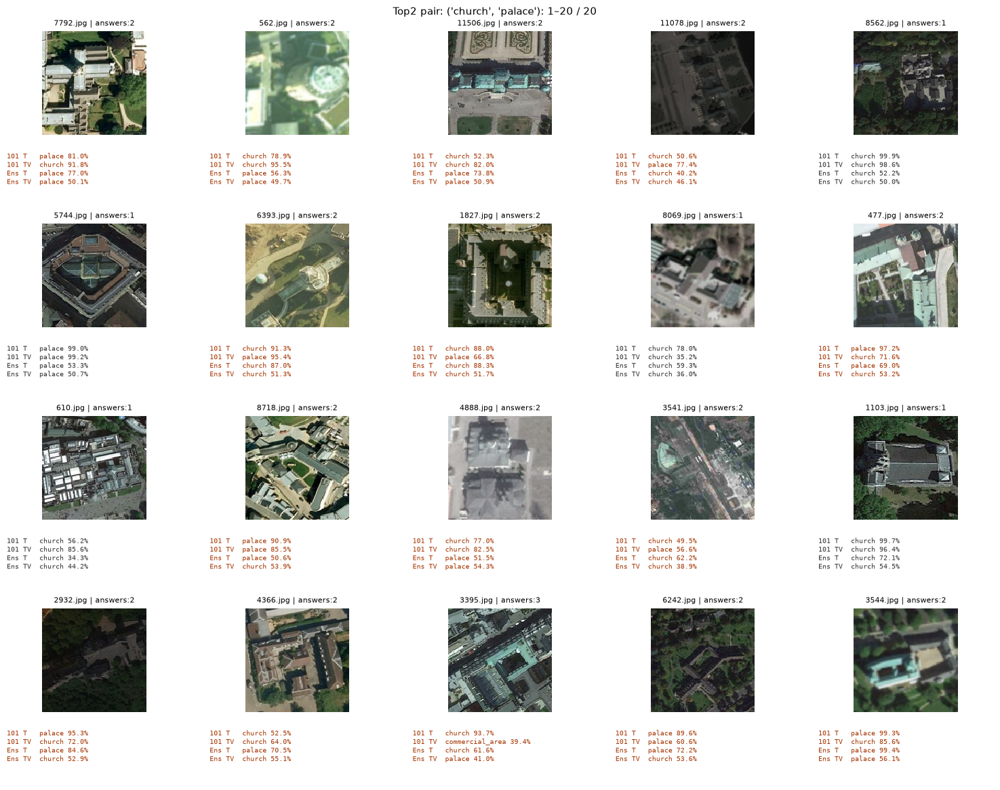

In [8]:
LEFT = 'ensemble_train'
RIGHT = 'ensemble_train_val'
transitions = tables['transitions'].query('left == @LEFT and right == @RIGHT')
display(transitions.head(25))
PAIR = ('church','palace')
pair_cases = select_cases(cases,'pair',model=PRIMARY,pair=PAIR,limit=20)
_ = compact_gallery(pair_cases,RAW_DIR/'test',title=f'Top2 pair: {PAIR}',columns=COLUMNS,
                page_size=PAGE_SIZE,thumbnail=THUMBNAIL)


## 8. Детальный просмотр ID: изображение и top5 каждой модели

По умолчанию показаны четыре ID из подборок неуверенности и расхождений. Для своего снимка задайте `IMAGE_IDS=['1234.jpg']`. Здесь полный кадр и top5 четырёх submission-вариантов, а также двух исходных ResNet50 D4. Это помогает понять, почему уверенная101 после усреднения даёт почти50/50: её ответ может противоречить50. Дополнительного inference нет.


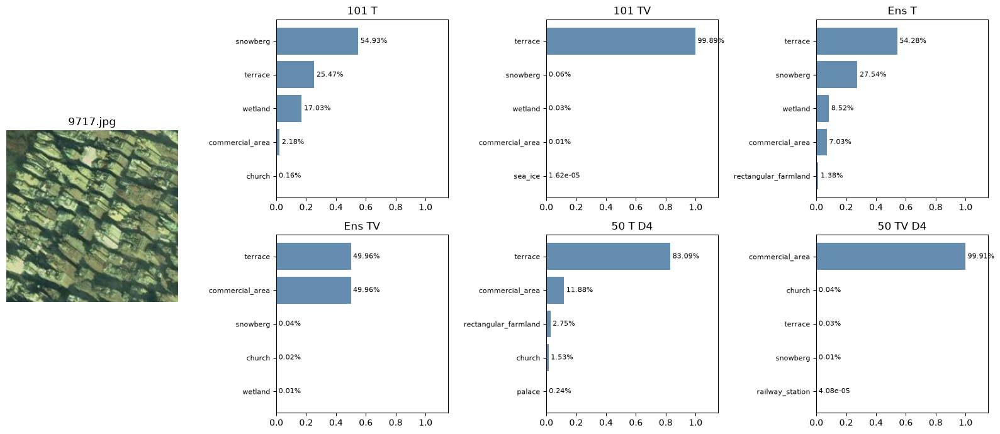

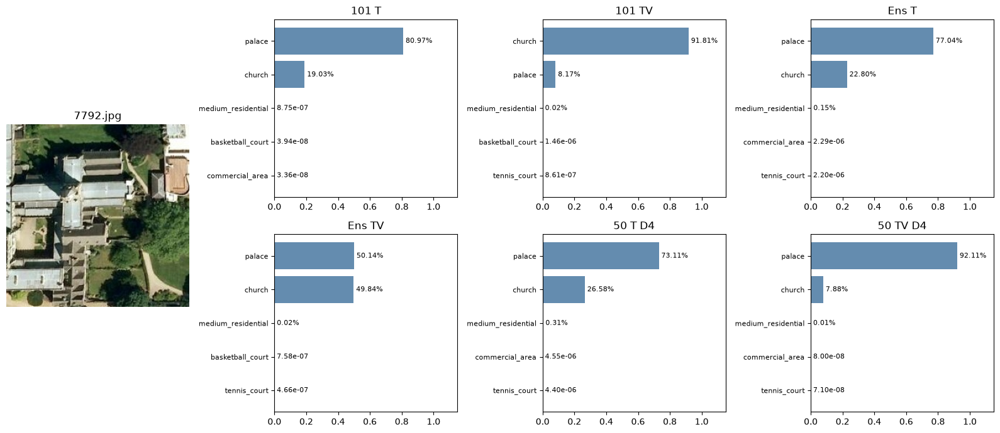

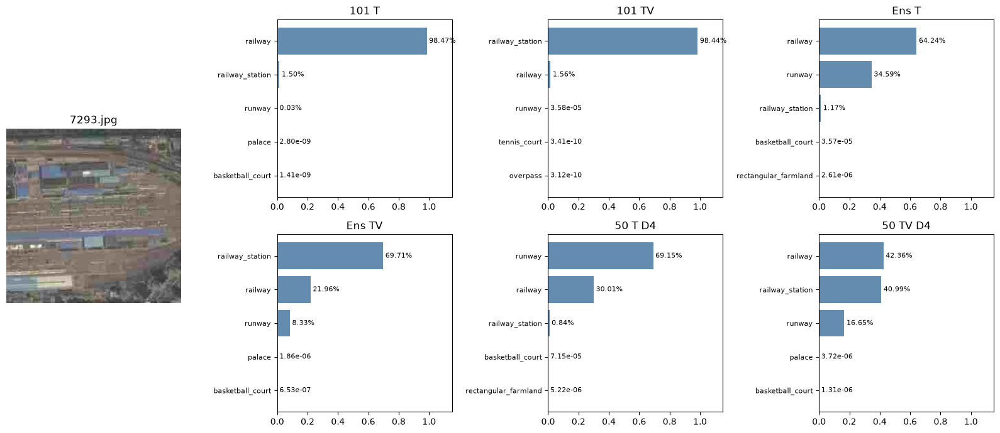

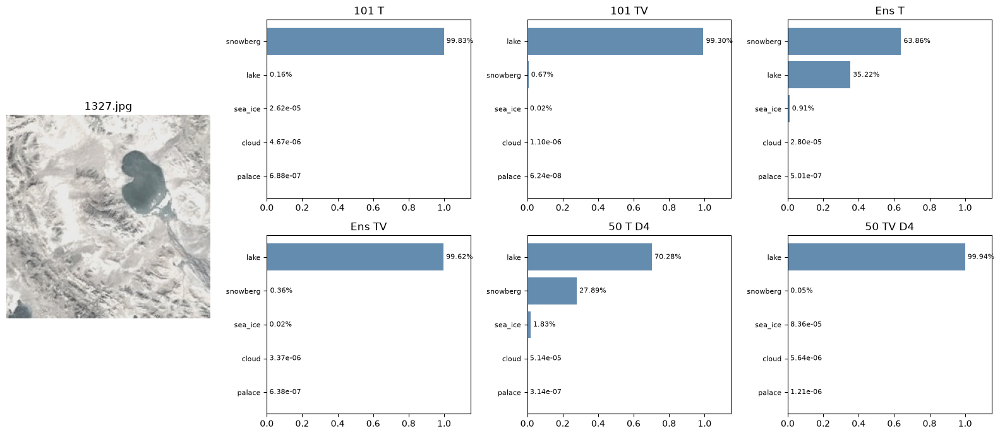

In [9]:
IMAGE_IDS = list(dict.fromkeys(uncertain_cases.id.head(2).tolist()+disagreement_cases.id.head(2).tolist()))
_ = probability_detail(IMAGE_IDS,{**members,'train50':source_members['train50'],'refit50':source_members['refit50']},classes,RAW_DIR/'test',top_k=5)


## Как интерпретировать

Галереи описывают поведение моделей. Без тестовых меток нельзя подсчитать, сколько изменённых ответов стали правильными, или автоматически разметить найденные снимки. Этот notebook не обучает модели, не подбирает пороги и не использует test для fitting preprocessing, representations или calibration.

Public scores подтверждают небольшую пользу refit и ансамбля на public части. Они не доказывают тот же прирост на private части. Прежние 97.14% val после многократного выбора рецепта не являются гарантией такого же качества на test.
